# Xem du lieu

|File	|Nội dung|	Số lượng|
| --- | --- | --- |
|test-images-idx3-ubyte.gz	|Ảnh tập train|	60.000|
|train-labels-idx1-ubyte.gz |Nhãn tương ứng của ảnh train|  60.000|
|t10k-images-idx3-ubyte.gz	|Ảnh tập test|	10.000|
|t10k-labels-idx1-ubyte.gz	|Nhãn tương ứng của ảnh test|	10.000|



In [2]:
from pathlib import Path
from torchvision.datasets import MNIST

current_dir = Path.cwd()
PROJECT_ROOT = current_dir.parent 
RAW_DIR = PROJECT_ROOT / "data"
RAW_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Dataset path:", RAW_DIR)

train_dataset = MNIST(
    root=str(RAW_DIR),
    train=True,
    download=True
)

test_dataset = MNIST(
    root=str(RAW_DIR),
    train=False,
    download=True 
)

Project root: /home/tim/General Code/Pattern_Recognition/WriteRHand
Dataset path: /home/tim/General Code/Pattern_Recognition/WriteRHand/data


## Kiểu dữ liệu & kích thước

In [3]:
print("Kiểu của đối tượng train_dataset:", type(train_dataset))
print("Kiểu của đối tượng test_dataset:", type(test_dataset))
print("Kích thước của đối tượng train_dataset:", type(train_dataset))
print("Kích thước của đối tượng test_dataset:", type(test_dataset))

Kiểu của đối tượng train_dataset: <class 'torchvision.datasets.mnist.MNIST'>
Kiểu của đối tượng test_dataset: <class 'torchvision.datasets.mnist.MNIST'>
Kích thước của đối tượng train_dataset: <class 'torchvision.datasets.mnist.MNIST'>
Kích thước của đối tượng test_dataset: <class 'torchvision.datasets.mnist.MNIST'>


Kiểu dữ liệu khi tải về mà không dùng `MNIST(... , transform=transform)` là một object dataset, cần biến đổi về dạng có thể xử lý.

In [4]:
train_images = train_dataset.data
train_labels = train_dataset.targets
print("Kieu du lieu cua train_dataset.data:", type(train_images))
print("Kieu du lieu cua train_dataset.targets:", type(train_labels))
print("Shape cua train_images:", train_images.shape)
print("Dtype cua train_images:", train_images.dtype)
print("Shape cua train_labels:", train_labels.shape)
print("Dtype cua train_labels:", train_labels.dtype)

Kieu du lieu cua train_dataset.data: <class 'torch.Tensor'>
Kieu du lieu cua train_dataset.targets: <class 'torch.Tensor'>
Shape cua train_images: torch.Size([60000, 28, 28])
Dtype cua train_images: torch.uint8
Shape cua train_labels: torch.Size([60000])
Dtype cua train_labels: torch.int64


`uint8` (Unsigned Integer 8-bit) là kiểu dữ liệu số nguyên không dấu 8-bit, lưu trữ các giá trị từ 0 đến 255 và là định dạng chuẩn để biểu diễn cường độ sáng của pixel ảnh (0 là đen, 255 là trắng)

In [5]:
test_images = test_dataset.data
test_labels = test_dataset.targets
print("Kieu du lieu cua test_dataset.data:", type(test_images))
print("Kieu du lieu cua test_dataset.targets:", type(test_labels))
print("Shape cua test_images:", test_images.shape)
print("Dtype cua test_images:", test_images.dtype)
print("Shape cua test_labels:", test_labels.shape)
print("Dtype cua test_labels:", test_labels.dtype)

Kieu du lieu cua test_dataset.data: <class 'torch.Tensor'>
Kieu du lieu cua test_dataset.targets: <class 'torch.Tensor'>
Shape cua test_images: torch.Size([10000, 28, 28])
Dtype cua test_images: torch.uint8
Shape cua test_labels: torch.Size([10000])
Dtype cua test_labels: torch.int64


In [6]:
print(train_images[0].shape)
print(train_images[0])

torch.Size([28, 28])
tensor([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,  18,
          18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,   0,   0],
        [  0,   0,   0,  

Mỗi dòng sample image là 1 ma trận 28x28 chứa các giá trị uint8 thể hiện độ sáng pixel

In [7]:
print(train_labels[0])
print(train_labels[2])
print(train_labels[4])

tensor(5)
tensor(4)
tensor(9)


## Vẽ ảnh & phân phối nhãn

In [8]:
print("Min, max pixel trong tap train:", train_images.min().item(),
      train_images.max().item())
print("Min, max pixel trong tap test:", test_images.min().item(),
      test_images.max().item())

Min, max pixel trong tap train: 0 255
Min, max pixel trong tap test: 0 255


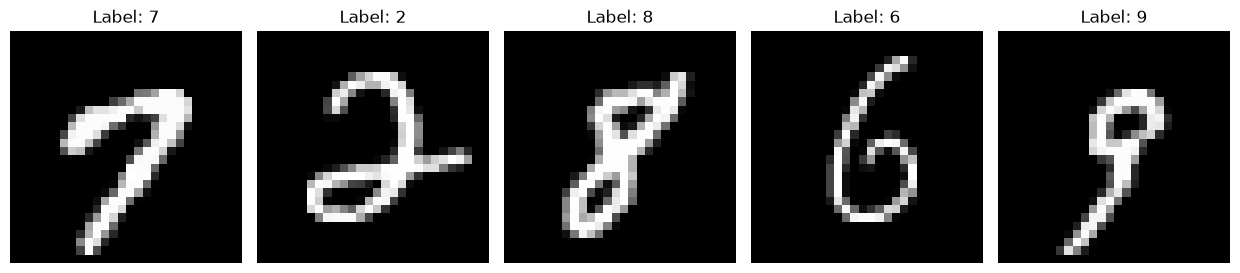

In [9]:
import matplotlib.pyplot as plt

def show_samples(images, labels, start=0, n=5):
    end = min(start + n, len(images))

    fig, axes = plt.subplots(
        1, end - start,
        figsize=(2.5 * (end - start), 3),
        squeeze=False # de ve mot hang n bieu do
    )

    for ax, i in zip(axes[0], range(start, end)):
        image = images[i]
        label = labels[i].item()


        ax.imshow(image, cmap="gray")
        ax.set_title(f"Label: {label}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()

show_samples(train_images, train_labels, start=15)

In [10]:
import torch

def label_count(labels):
    labs, counts = torch.unique(labels, return_counts=True)
    n = len(labels)
    for label, count in zip(labs, counts):
        print(f"Nhãn: {label}: {count},    tỷ lệ: {count*100/n:.1f}%")

label_count(train_labels)

Nhãn: 0: 5923,    tỷ lệ: 9.9%
Nhãn: 1: 6742,    tỷ lệ: 11.2%
Nhãn: 2: 5958,    tỷ lệ: 9.9%
Nhãn: 3: 6131,    tỷ lệ: 10.2%
Nhãn: 4: 5842,    tỷ lệ: 9.7%
Nhãn: 5: 5421,    tỷ lệ: 9.0%
Nhãn: 6: 5918,    tỷ lệ: 9.9%
Nhãn: 7: 6265,    tỷ lệ: 10.4%
Nhãn: 8: 5851,    tỷ lệ: 9.8%
Nhãn: 9: 5949,    tỷ lệ: 9.9%


Nhận xét: các nhãn có phân bố đồng đều, không quá xa 10%. Nhãn 1 nhiều nhất (11.2%), nhãn 5 ít nhất (9%)

# Xử lý dữ liệu

In [11]:
SEED = 42
torch.manual_seed(SEED)

g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(train_images), generator=g)
tr_idx, va_idx = perm[:50000], perm[50000:]

_X = train_images[tr_idx].reshape(-1, 784).float() / 255.0
MEAN, STD = _X.mean().item(), _X.std().item()


def preprocess(X_raw):
    return (X_raw.reshape(-1, 784).float() / 255.0 - MEAN) / STD


X_train, y_train = preprocess(train_images[tr_idx]), train_labels[tr_idx]
X_val, y_val = preprocess(train_images[va_idx]), train_labels[va_idx]
X_test, y_test = preprocess(test_images), test_labels

print(f"MEAN = {MEAN:.4f}, STD = {STD:.4f}")
print("X_train", tuple(X_train.shape), "| X_val", tuple(X_val.shape), "| X_test", tuple(X_test.shape))
print("So mau moi lop (train):", torch.bincount(y_train).tolist())

MEAN = 0.1307, STD = 0.3082
X_train (50000, 784) | X_val (10000, 784) | X_test (10000, 784)
So mau moi lop (train): [4923, 5613, 4958, 5093, 4863, 4546, 4933, 5204, 4882, 4985]
